In [ ]:
%pip install --upgrade torch torchvision scikit-learn matplotlib pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 970.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 117.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 111.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 119.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 118.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.0/248.0 MB 4.7 MB/s eta 0:00:00
  Attempting uninstall: nvidia-cusparselt-cu13
    Found existing installation: nvidia-cusparselt-cu13 0.8.0
    Uninstalling

In [ ]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
CUDA available: True
Device: GPU


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU not allocated. Check Runtime > Change runtime type.")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GB):", round(
    torch.cuda.get_device_properties(0).total_memory / 1e9, 2
))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64


In [ ]:
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# CIFAR-10 preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

# Download datasets
full_train = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Split training data: 45,000 train + 5,000 validation
train_dataset, val_dataset = random_split(
    full_train,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

# Data loaders
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

class_names = full_train.classes

print("Dataset loaded successfully!")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Classes:", class_names)
print("GPU:", torch.cuda.get_device_name(0))

100%|██████████| 170M/170M [29:49<00:00, 95.3kB/s]


Dataset loaded successfully!
Training images: 45000
Validation images: 5000
Testing images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
GPU: Tesla T4


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type != "cuda":
    raise RuntimeError("GPU is not available. Enable T4 GPU in Colab.")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
model = CNN().to(device)

print(model)
print("\nModel device:", next(model.parameters()).device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

Model device: cuda:0
Total parameters: 620810


In [ ]:
import time
import torch
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=8)

scaler = torch.amp.GradScaler("cuda")

EPOCHS = 8
best_val_acc = 0.0
history = {"train_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    start_time = time.time()

    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(images)

            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total
    val_acc = 100 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_teacher.pth")

    scheduler.step()

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Time: {time.time()-start_time:.1f}s"
    )

print(f"\nBest validation accuracy: {best_val_acc:.2f}%")
print("Best teacher saved to best_teacher.pth")

Epoch [1/8] Loss: 1.2486 | Train Acc: 54.95% | Val Acc: 64.76% | Time: 13.5s
Epoch [2/8] Loss: 0.8455 | Train Acc: 70.18% | Val Acc: 68.58% | Time: 11.6s
Epoch [3/8] Loss: 0.6872 | Train Acc: 75.88% | Val Acc: 73.98% | Time: 11.6s
Epoch [4/8] Loss: 0.5812 | Train Acc: 79.68% | Val Acc: 75.88% | Time: 12.1s
Epoch [5/8] Loss: 0.4793 | Train Acc: 83.54% | Val Acc: 76.12% | Time: 11.5s
Epoch [6/8] Loss: 0.3913 | Train Acc: 86.84% | Val Acc: 78.04% | Time: 11.8s
Epoch [7/8] Loss: 0.3242 | Train Acc: 89.44% | Val Acc: 78.62% | Time: 11.5s
Epoch [8/8] Loss: 0.2839 | Train Acc: 91.19% | Val Acc: 79.44% | Time: 11.6s

Best validation accuracy: 79.44%
Best teacher saved to best_teacher.pth


In [ ]:
import torch
import torch.nn.functional as F

# Load the best teacher checkpoint
model.load_state_dict(
    torch.load("best_teacher.pth", map_location=device, weights_only=True)
)
model.eval()

# Store activations and their gradients for each convolutional block
activations = {}
importance = {}

def save_activation(name):
    def hook(module, inputs, output):
        activations[name] = output
        output.retain_grad()
    return hook

handles = [
    model.conv1.register_forward_hook(save_activation("conv1")),
    model.conv2.register_forward_hook(save_activation("conv2")),
    model.conv3.register_forward_hook(save_activation("conv3"))
]

# Accumulate Taylor importance over a subset of training data
for name in ["conv1", "conv2", "conv3"]:
    importance[name] = None

NUM_BATCHES = 20

for batch_idx, (images, labels) in enumerate(train_loader):
    if batch_idx >= NUM_BATCHES:
        break

    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    model.zero_grad(set_to_none=True)
    activations.clear()

    outputs = model(images)
    loss = F.cross_entropy(outputs, labels)
    loss.backward()

    for name, activation in activations.items():
        # Mean |activation * gradient| over batch and spatial dimensions
        scores = (activation * activation.grad).abs().mean(dim=(0, 2, 3))

        if importance[name] is None:
            importance[name] = scores.detach().clone()
        else:
            importance[name] += scores.detach()

for handle in handles:
    handle.remove()

for name in importance:
    importance[name] /= NUM_BATCHES
    print(
        f"{name}: {len(importance[name])} channels, "
        f"importance range = "
        f"{importance[name].min().item():.6e} to "
        f"{importance[name].max().item():.6e}"
    )

print("\nTaylor channel importance calculated successfully.")

conv1: 32 channels, importance range = 1.469754e-06 to 1.613475e-05
conv2: 64 channels, importance range = 2.624851e-06 to 1.205276e-05
conv3: 128 channels, importance range = 3.591285e-06 to 3.031291e-05

Taylor channel importance calculated successfully.


In [ ]:
import numpy as np
import torch
import torch.nn as nn

# GA configuration
POPULATION_SIZE = 6
GENERATIONS = 3
PRUNE_MIN = 0.0
PRUNE_MAX = 0.50

# Evaluate on a fixed validation subset for faster GA search
ga_images, ga_labels = [], []

for images, labels in val_loader:
    ga_images.append(images)
    ga_labels.append(labels)
    if sum(x.size(0) for x in ga_images) >= 1024:
        break

ga_images = torch.cat(ga_images)[:1024].to(device)
ga_labels = torch.cat(ga_labels)[:1024].to(device)

layer_names = ["conv1", "conv2", "conv3"]
original_channels = np.array([32, 64, 128])

def evaluate_candidate(candidate):
    """
    candidate contains pruning ratios for conv1, conv2, conv3.
    Uses Taylor scores to estimate retained channels and a
    channel-masked teacher to evaluate validation accuracy.
    """
    model.eval()
    correct = 0
    total = ga_labels.size(0)

    with torch.no_grad():
        # Temporary channel masks based on Taylor importance.
        masks = {}
        for i, name in enumerate(layer_names):
            scores = importance[name]
            keep_count = max(
                1, int(original_channels[i] * (1 - candidate[i]))
            )
            keep_indices = torch.topk(scores, keep_count).indices
            mask = torch.zeros_like(scores)
            mask[keep_indices] = 1.0
            masks[name] = mask

        def mask_hook(name):
            def hook(module, inputs, output):
                return output * masks[name].view(1, -1, 1, 1)
            return hook

        hooks = [
            getattr(model, name).register_forward_hook(mask_hook(name))
            for name in layer_names
        ]

        outputs = model(ga_images)
        correct = (outputs.argmax(1) == ga_labels).sum().item()

        for hook in hooks:
            hook.remove()

    accuracy = correct / total

    # Estimated channel reduction; actual parameter reduction
    # will be measured after physical pruning.
    retained = sum(
        max(1, int(original_channels[i] * (1 - candidate[i])))
        for i in range(3)
    )
    reduction = 1 - retained / original_channels.sum()

    return accuracy + 0.15 * reduction

def initialize_population():
    return np.random.uniform(
        PRUNE_MIN, PRUNE_MAX, size=(POPULATION_SIZE, 3)
    )

population = initialize_population()
best_candidate = None
best_fitness = -float("inf")

for generation in range(GENERATIONS):
    fitness = np.array([
        evaluate_candidate(candidate) for candidate in population
    ])

    best_idx = np.argmax(fitness)
    if fitness[best_idx] > best_fitness:
        best_fitness = fitness[best_idx]
        best_candidate = population[best_idx].copy()

    print(
        f"Generation {generation + 1}/{GENERATIONS} | "
        f"Best fitness: {best_fitness:.4f} | "
        f"Pruning ratios: {np.round(best_candidate, 3)}"
    )

    # Keep the top two candidates as elites
    elite_indices = np.argsort(fitness)[-2:]
    next_population = [population[i].copy() for i in elite_indices]

    while len(next_population) < POPULATION_SIZE:
        parent1, parent2 = population[
            np.random.choice(elite_indices, size=2, replace=True)
        ]
        child = (parent1 + parent2) / 2

        # Mutation
        child += np.random.normal(0, 0.08, size=3)
        child = np.clip(child, PRUNE_MIN, PRUNE_MAX)
        next_population.append(child)

    population = np.array(next_population)

print("\nBest pruning ratios:", np.round(best_candidate, 3))
print("Best GA fitness:", round(best_fitness, 4))

Generation 1/3 | Best fitness: 0.7049 | Pruning ratios: [0.103 0.035 0.295]
Generation 2/3 | Best fitness: 0.7049 | Pruning ratios: [0.103 0.035 0.295]
Generation 3/3 | Best fitness: 0.7335 | Pruning ratios: [0.095 0.    0.26 ]

Best pruning ratios: [0.095 0.    0.26 ]
Best GA fitness: 0.7335


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Convert GA ratios into retained channel indices using Taylor importance
keep_indices = {}

for i, name in enumerate(layer_names):
    scores = importance[name]
    keep_count = max(
        1,
        int(original_channels[i] * (1 - best_candidate[i]))
    )
    keep_indices[name] = torch.topk(scores, keep_count).indices.sort().values

print("Channels retained:")
for name in layer_names:
    print(f"{name}: {len(keep_indices[name])}")

class PrunedCNN(nn.Module):
    def __init__(self, teacher, keep_indices):
        super().__init__()

        idx1 = keep_indices["conv1"]
        idx2 = keep_indices["conv2"]
        idx3 = keep_indices["conv3"]

        c1, c2, c3 = len(idx1), len(idx2), len(idx3)

        # Convolution 1: keep selected output channels
        self.conv1 = nn.Conv2d(3, c1, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(c1)

        # Convolution 2: prune both input and output channels
        self.conv2 = nn.Conv2d(c1, c2, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(c2)

        # Convolution 3: prune both input and output channels
        self.conv3 = nn.Conv2d(c2, c3, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(c3)

        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(c3 * 4 * 4, teacher.fc1.out_features)
        self.fc2 = nn.Linear(teacher.fc2.in_features, teacher.fc2.out_features)

        # Copy retained convolution weights and biases
        with torch.no_grad():
            self.conv1.weight.copy_(teacher.conv1.weight[idx1])
            self.conv1.bias.copy_(teacher.conv1.bias[idx1])

            self.bn1.load_state_dict({
                "weight": teacher.bn1.weight[idx1].clone(),
                "bias": teacher.bn1.bias[idx1].clone(),
                "running_mean": teacher.bn1.running_mean[idx1].clone(),
                "running_var": teacher.bn1.running_var[idx1].clone(),
                "num_batches_tracked": teacher.bn1.num_batches_tracked.clone()
            })

            self.conv2.weight.copy_(
                teacher.conv2.weight[idx2][:, idx1]
            )
            self.conv2.bias.copy_(teacher.conv2.bias[idx2])

            self.bn2.load_state_dict({
                "weight": teacher.bn2.weight[idx2].clone(),
                "bias": teacher.bn2.bias[idx2].clone(),
                "running_mean": teacher.bn2.running_mean[idx2].clone(),
                "running_var": teacher.bn2.running_var[idx2].clone(),
                "num_batches_tracked": teacher.bn2.num_batches_tracked.clone()
            })

            self.conv3.weight.copy_(
                teacher.conv3.weight[idx3][:, idx2]
            )
            self.conv3.bias.copy_(teacher.conv3.bias[idx3])

            self.bn3.load_state_dict({
                "weight": teacher.bn3.weight[idx3].clone(),
                "bias": teacher.bn3.bias[idx3].clone(),
                "running_mean": teacher.bn3.running_mean[idx3].clone(),
                "running_var": teacher.bn3.running_var[idx3].clone(),
                "num_batches_tracked": teacher.bn3.num_batches_tracked.clone()
            })

            # Match the retained channels in the classifier
            fc_indices = torch.cat([
                idx3 * 16 + offset for offset in range(16)
            ]).sort().values

            self.fc1.weight.copy_(teacher.fc1.weight[:, fc_indices])
            self.fc1.bias.copy_(teacher.fc1.bias)
            self.fc2.weight.copy_(teacher.fc2.weight)
            self.fc2.bias.copy_(teacher.fc2.bias)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

pruned_model = PrunedCNN(model, keep_indices).to(device)

original_params = sum(p.numel() for p in model.parameters())
pruned_params = sum(p.numel() for p in pruned_model.parameters())
reduction = 100 * (1 - pruned_params / original_params)

print("\nPhysical pruning completed.")
print("Original parameters:", original_params)
print("Pruned parameters:", pruned_params)
print(f"Parameter reduction: {reduction:.2f}%")
print("Pruned model device:", next(pruned_model.parameters()).device)

Channels retained:
conv1: 28
conv2: 64
conv3: 94

Physical pruning completed.
Original parameters: 620810
Pruned parameters: 459436
Parameter reduction: 25.99%
Pruned model device: cuda:0


In [ ]:
import torch

def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(images)

            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return 100.0 * correct / total

teacher_val_acc = evaluate_accuracy(model, val_loader)
pruned_val_acc = evaluate_accuracy(pruned_model, val_loader)

print(f"Teacher validation accuracy: {teacher_val_acc:.2f}%")
print(f"Pruned student validation accuracy: {pruned_val_acc:.2f}%")
print(f"Accuracy difference: {teacher_val_acc - pruned_val_acc:.2f} percentage points")

Teacher validation accuracy: 79.44%
Pruned student validation accuracy: 61.64%
Accuracy difference: 17.80 percentage points


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import time

# Freeze the teacher; it must not change during distillation
model.eval()
for param in model.parameters():
    param.requires_grad = False

student = pruned_model
student.train()

optimizer_kd = optim.AdamW(
    student.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

EPOCHS_KD = 8
TEMPERATURE = 4.0
ALPHA = 0.7  # Weight given to distillation loss

scaler_kd = torch.amp.GradScaler("cuda")
kd_history = {"train_loss": [], "val_acc": []}
best_kd_acc = 0.0

for epoch in range(EPOCHS_KD):
    start_time = time.time()
    student.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_kd.zero_grad(set_to_none=True)

        # Teacher produces targets without gradients
        with torch.no_grad():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                teacher_logits = model(images)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            student_logits = student(images)

            hard_loss = F.cross_entropy(student_logits, labels)

            soft_loss = F.kl_div(
                F.log_softmax(student_logits / TEMPERATURE, dim=1),
                F.softmax(teacher_logits / TEMPERATURE, dim=1),
                reduction="batchmean"
            ) * (TEMPERATURE ** 2)

            loss = (1 - ALPHA) * hard_loss + ALPHA * soft_loss

        scaler_kd.scale(loss).backward()
        scaler_kd.step(optimizer_kd)
        scaler_kd.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (student_logits.argmax(1) == labels).sum().item()
        total_samples += batch_size

    train_loss = total_loss / total_samples
    train_acc = 100 * total_correct / total_samples
    val_acc = evaluate_accuracy(student, val_loader)

    kd_history["train_loss"].append(train_loss)
    kd_history["val_acc"].append(val_acc)

    if val_acc > best_kd_acc:
        best_kd_acc = val_acc
        torch.save(student.state_dict(), "best_student_kd.pth")

    print(
        f"Epoch [{epoch + 1}/{EPOCHS_KD}] "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Time: {time.time() - start_time:.1f}s"
    )

print(f"\nBest KD student validation accuracy: {best_kd_acc:.2f}%")
print("Best student saved to best_student_kd.pth")

Epoch [1/8] Loss: 0.3166 | Train Acc: 86.17% | Val Acc: 75.66% | Time: 13.6s
Epoch [2/8] Loss: 0.2357 | Train Acc: 88.04% | Val Acc: 78.04% | Time: 12.4s
Epoch [3/8] Loss: 0.2124 | Train Acc: 88.95% | Val Acc: 77.42% | Time: 12.4s
Epoch [4/8] Loss: 0.2063 | Train Acc: 89.51% | Val Acc: 78.44% | Time: 12.4s
Epoch [5/8] Loss: 0.2113 | Train Acc: 89.63% | Val Acc: 77.22% | Time: 12.1s
Epoch [6/8] Loss: 0.2061 | Train Acc: 89.97% | Val Acc: 78.62% | Time: 12.2s
Epoch [7/8] Loss: 0.1943 | Train Acc: 90.25% | Val Acc: 78.00% | Time: 12.3s
Epoch [8/8] Loss: 0.1955 | Train Acc: 90.74% | Val Acc: 78.98% | Time: 12.4s

Best KD student validation accuracy: 78.98%
Best student saved to best_student_kd.pth


In [ ]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Restore the best student checkpoint
student.load_state_dict(
    torch.load(
        "best_student_kd.pth",
        map_location=device,
        weights_only=True
    )
)
student.eval()

y_true = []
teacher_preds = []
student_preds = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels_gpu = labels.to(device, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            teacher_outputs = model(images)
            student_outputs = student(images)

        y_true.extend(labels.cpu().numpy())
        teacher_preds.extend(teacher_outputs.argmax(1).cpu().numpy())
        student_preds.extend(student_outputs.argmax(1).cpu().numpy())

def report_metrics(y_true, predictions, model_name):
    print(f"\n{model_name}")
    print("-" * 40)
    print(f"Accuracy:  {100 * accuracy_score(y_true, predictions):.2f}%")
    print(f"Precision: {precision_score(y_true, predictions, average='macro', zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, predictions, average='macro', zero_division=0):.4f}")
    print(f"Macro F1:  {f1_score(y_true, predictions, average='macro', zero_division=0):.4f}")

report_metrics(y_true, teacher_preds, "Teacher — Test Set")
report_metrics(y_true, student_preds, "Pruned Student with KD — Test Set")

print("\nStudent classification report:")
print(classification_report(
    y_true,
    student_preds,
    target_names=class_names,
    zero_division=0
))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (



Teacher — Test Set
----------------------------------------
Accuracy:  79.33%
Precision: 0.7924
Recall:    0.7933
Macro F1:  0.7927

Pruned Student with KD — Test Set
----------------------------------------
Accuracy:  79.00%
Precision: 0.7905
Recall:    0.7900
Macro F1:  0.7899

Student classification report:
              precision    recall  f1-score   support

    airplane       0.81      0.82      0.81      1000
  automobile       0.90      0.88      0.89      1000
        bird       0.70      0.73      0.71      1000
         cat       0.63      0.60      0.62      1000
        deer       0.76      0.75      0.75      1000
         dog       0.71      0.72      0.71      1000
        frog       0.80      0.87      0.83      1000
       horse       0.85      0.80      0.83      1000
        ship       0.87      0.89      0.88      1000
       truck       0.88      0.84      0.86      1000

    accuracy                           0.79     10000
   macro avg       0.79      0.79    

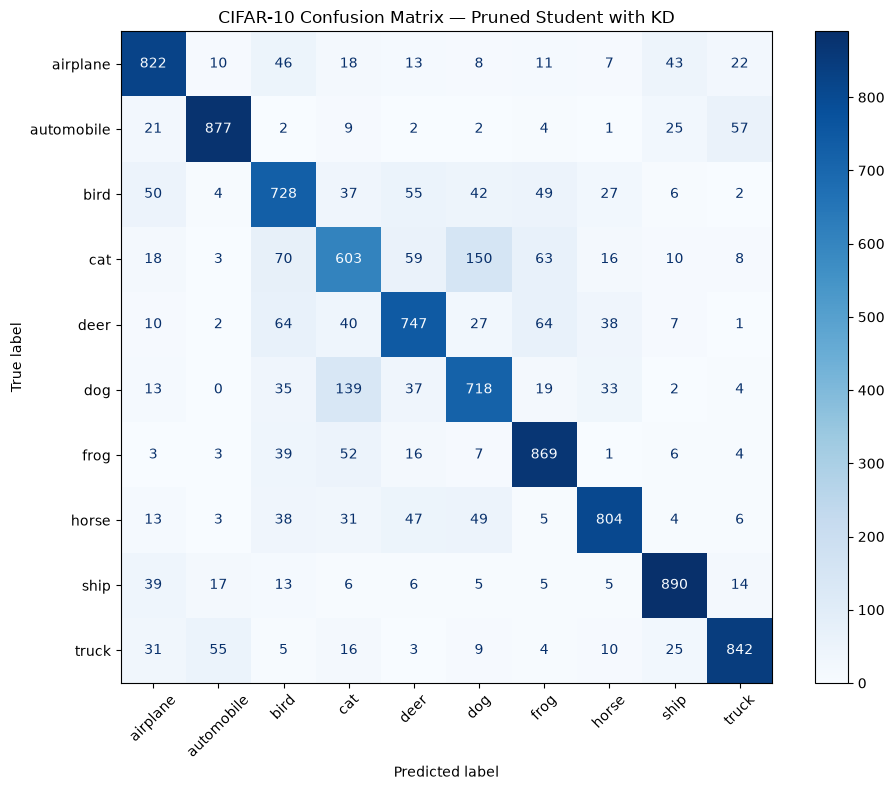

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, student_preds)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")

ax.set_title("CIFAR-10 Confusion Matrix — Pruned Student with KD")
plt.tight_layout()
plt.show()

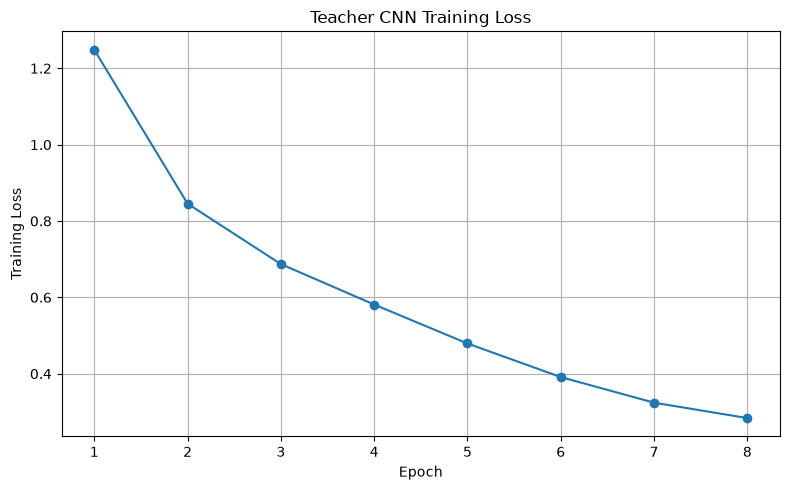

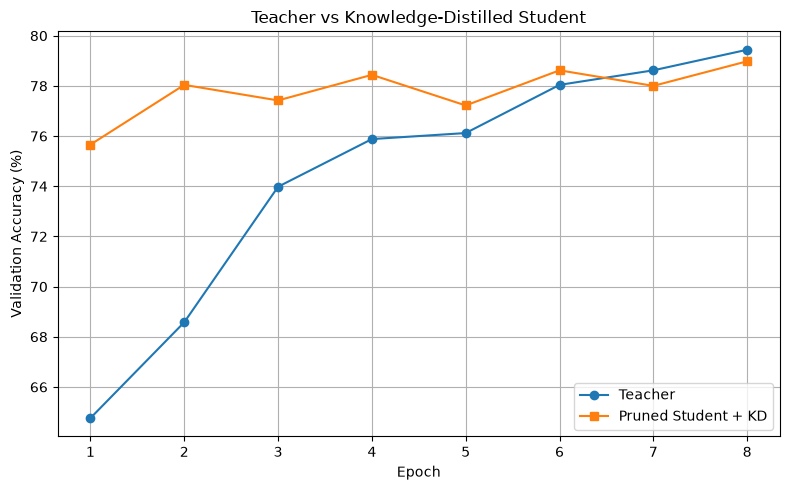

Best teacher validation accuracy: 79.44%
Best student validation accuracy: 78.98%


In [ ]:
import matplotlib.pyplot as plt

epochs_teacher = range(1, len(history["train_loss"]) + 1)
epochs_kd = range(1, len(kd_history["train_loss"]) + 1)

# Plot 1: Teacher training loss
plt.figure(figsize=(8, 5))
plt.plot(epochs_teacher, history["train_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Teacher CNN Training Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot 2: Teacher and student validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs_teacher, history["val_acc"], marker="o", label="Teacher")
plt.plot(epochs_kd, kd_history["val_acc"], marker="s", label="Pruned Student + KD")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Teacher vs Knowledge-Distilled Student")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Best teacher validation accuracy: {max(history['val_acc']):.2f}%")
print(f"Best student validation accuracy: {max(kd_history['val_acc']):.2f}%")

In [ ]:
import time
import pandas as pd
import torch

def count_parameters(net):
    return sum(p.numel() for p in net.parameters())

def measure_latency(net, input_shape=(1, 3, 32, 32), warmup=50, runs=300):
    net.eval()
    sample = torch.randn(*input_shape, device=device)

    with torch.inference_mode():
        for _ in range(warmup):
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                net(sample)

        torch.cuda.synchronize()
        start = time.perf_counter()

        for _ in range(runs):
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                net(sample)

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

    return elapsed * 1000 / runs

teacher_params = count_parameters(model)
student_params = count_parameters(student)

teacher_latency = measure_latency(model)
student_latency = measure_latency(student)

results = pd.DataFrame([
    {
        "Model": "Teacher CNN",
        "Test Accuracy (%)": 79.33,
        "Parameters": teacher_params,
        "Latency (ms/image)": teacher_latency
    },
    {
        "Model": "Pruned CNN + KD",
        "Test Accuracy (%)": 79.00,
        "Parameters": student_params,
        "Latency (ms/image)": student_latency
    }
])

print(results.to_string(index=False))
print(f"\nParameter reduction: {(1 - student_params / teacher_params) * 100:.2f}%")
print(f"Latency change: {(1 - student_latency / teacher_latency) * 100:.2f}%")

          Model  Test Accuracy (%)  Parameters  Latency (ms/image)
    Teacher CNN              79.33      620810            1.348839
Pruned CNN + KD              79.00      459436            1.664535

Parameter reduction: 25.99%
Latency change: -23.41%


In [ ]:
import torch
import torch.nn as nn
import pandas as pd

def calculate_macs(net):
    macs = 0
    handles = []

    def conv_hook(module, inputs, output):
        nonlocal macs
        kernel_ops = (
            module.kernel_size[0] * module.kernel_size[1]
            * (module.in_channels // module.groups)
        )
        macs += output.numel() * kernel_ops

    def linear_hook(module, inputs, output):
        nonlocal macs
        macs += output.numel() * module.in_features

    for layer in net.modules():
        if isinstance(layer, nn.Conv2d):
            handles.append(layer.register_forward_hook(conv_hook))
        elif isinstance(layer, nn.Linear):
            handles.append(layer.register_forward_hook(linear_hook))

    net.eval()
    sample = torch.randn(1, 3, 32, 32, device=device)

    with torch.inference_mode():
        net(sample)

    for handle in handles:
        handle.remove()

    return macs

teacher_macs = calculate_macs(model)
student_macs = calculate_macs(student)

compute_results = pd.DataFrame([
    {
        "Model": "Teacher CNN",
        "MACs (M)": teacher_macs / 1e6,
        "Approx FLOPs (M)": 2 * teacher_macs / 1e6
    },
    {
        "Model": "Pruned CNN + KD",
        "MACs (M)": student_macs / 1e6,
        "Approx FLOPs (M)": 2 * student_macs / 1e6
    }
])

print(compute_results.round(3).to_string(index=False))
print(
    f"\nMAC reduction: "
    f"{100 * (1 - student_macs / teacher_macs):.2f}%"
)

          Model  MACs (M)  Approx FLOPs (M)
    Teacher CNN    10.849            21.698
Pruned CNN + KD     8.756            17.511

MAC reduction: 19.29%


In [ ]:
import pandas as pd
import torch
import os

# Create final comparison table
final_results = pd.DataFrame([
    {
        "Model": "Teacher CNN",
        "Test Accuracy (%)": 79.33,
        "Macro Precision": 0.7924,
        "Macro Recall": 0.7933,
        "Macro F1": 0.7927,
        "Parameters": teacher_params,
        "MACs (M)": teacher_macs / 1e6,
        "FLOPs (M)": 2 * teacher_macs / 1e6,
        "Latency (ms/image)": teacher_latency
    },
    {
        "Model": "GA-Pruned CNN + KD",
        "Test Accuracy (%)": 79.00,
        "Macro Precision": 0.7905,
        "Macro Recall": 0.7900,
        "Macro F1": 0.7899,
        "Parameters": student_params,
        "MACs (M)": student_macs / 1e6,
        "FLOPs (M)": 2 * student_macs / 1e6,
        "Latency (ms/image)": student_latency
    }
])

# Save the best teacher and distilled student
torch.save(model.state_dict(), "teacher_cifar10.pth")
torch.save(student.state_dict(), "pruned_student_kd_cifar10.pth")

# Save results and pruning information
final_results.to_csv("final_comparison_results.csv", index=False)

pd.DataFrame({
    "Layer": layer_names,
    "Original Channels": original_channels,
    "Retained Channels": [len(keep_indices[name]) for name in layer_names],
    "Pruning Ratio (%)": [
        100 * (1 - len(keep_indices[name]) / original_channels[i])
        for i, name in enumerate(layer_names)
    ]
}).to_csv("pruning_details.csv", index=False)

print("Final comparison:")
print(final_results.round(4).to_string(index=False))

print("\nSaved files:")
for filename in [
    "teacher_cifar10.pth",
    "pruned_student_kd_cifar10.pth",
    "final_comparison_results.csv",
    "pruning_details.csv"
]:
    print(f"{filename}: {os.path.getsize(filename) / 1024:.1f} KB")

print("\nAll results and checkpoints saved successfully.")

Final comparison:
             Model  Test Accuracy (%)  Macro Precision  Macro Recall  Macro F1  Parameters  MACs (M)  FLOPs (M)  Latency (ms/image)
       Teacher CNN              79.33           0.7924        0.7933    0.7927      620810   10.8488    21.6975              1.3488
GA-Pruned CNN + KD              79.00           0.7905        0.7900    0.7899      459436    8.7557    17.5114              1.6645

Saved files:
teacher_cifar10.pth: 2435.1 KB
pruned_student_kd_cifar10.pth: 1804.9 KB
final_comparison_results.csv: 0.3 KB
pruning_details.csv: 0.1 KB

All results and checkpoints saved successfully.


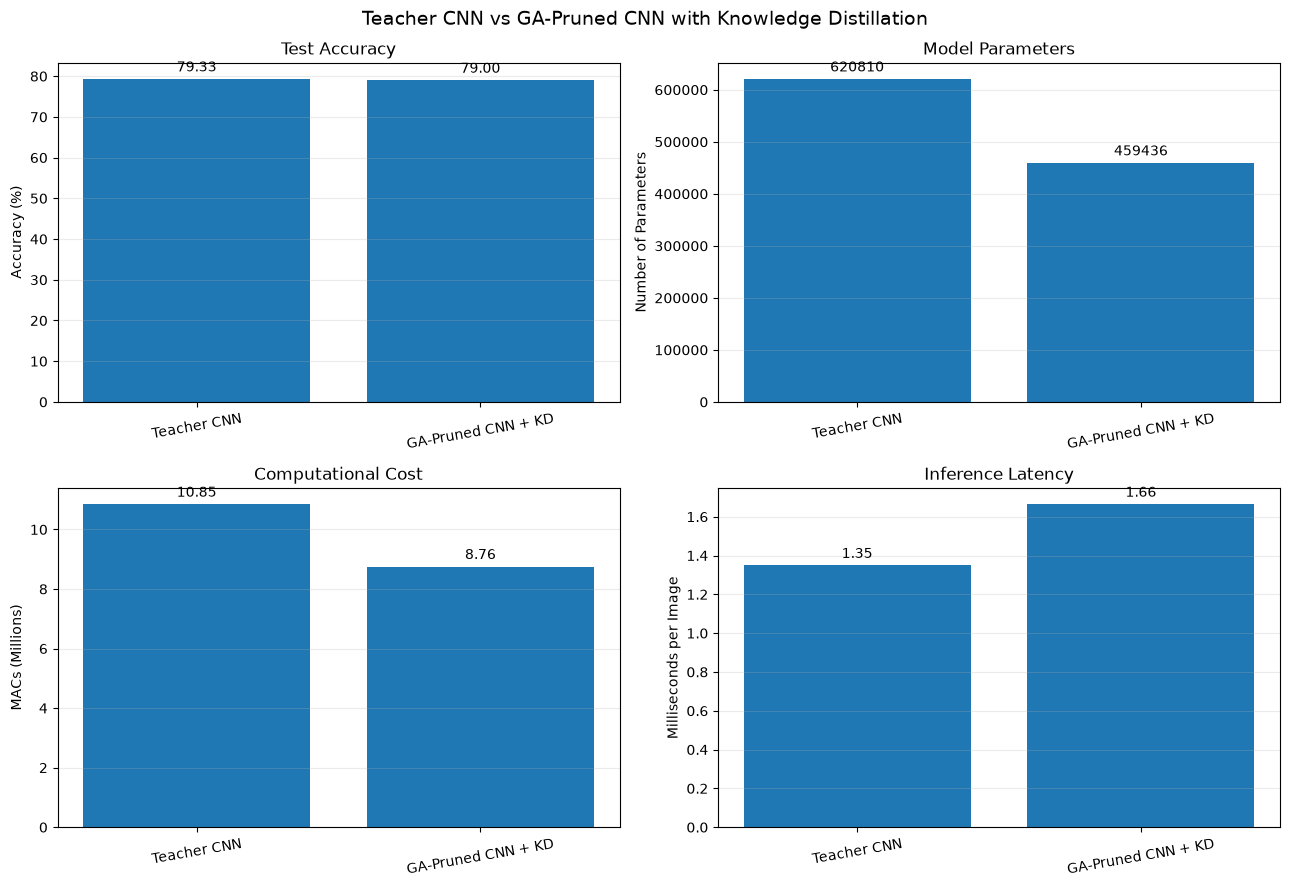

Saved: final_comparison_graphs.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Teacher CNN", "GA-Pruned CNN + KD"]

accuracies = [79.33, 79.00]
parameters = [620810, 459436]
macs = [10.8488, 8.7557]
latencies = [1.3488, 1.6645]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

plots = [
    (axes[0, 0], accuracies, "Test Accuracy", "Accuracy (%)"),
    (axes[0, 1], parameters, "Model Parameters", "Number of Parameters"),
    (axes[1, 0], macs, "Computational Cost", "MACs (Millions)"),
    (axes[1, 1], latencies, "Inference Latency", "Milliseconds per Image")
]

for ax, values, title, ylabel in plots:
    bars = ax.bar(models, values)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=10)
    ax.bar_label(bars, fmt="%.2f" if max(values) < 100 else "%.0f", padding=3)
    ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "Teacher CNN vs GA-Pruned CNN with Knowledge Distillation",
    fontsize=14
)
plt.tight_layout()
plt.savefig("final_comparison_graphs.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: final_comparison_graphs.png")

In [ ]:
print("=" * 65)
print("GA-BASED CNN PRUNING WITH KNOWLEDGE DISTILLATION")
print("FINAL PROJECT SUMMARY")
print("=" * 65)

print("\n1. DATASET")
print("Dataset       : CIFAR-10")
print("Training      : 45,000 images")
print("Validation    : 5,000 images")
print("Testing       : 10,000 images")
print("Classes       : 10")

print("\n2. TEACHER MODEL")
print(f"Parameters    : {620810:,}")
print("Test Accuracy : 79.33%")
print(f"MACs          : {10.8488:.4f} million")
print(f"Latency       : {1.3488:.4f} ms/image")

print("\n3. PRUNED STUDENT WITH KNOWLEDGE DISTILLATION")
print(f"Parameters    : {459436:,}")
print("Test Accuracy : 79.00%")
print(f"MACs          : {8.7557:.4f} million")
print(f"Latency       : {1.6645:.4f} ms/image")

print("\n4. IMPROVEMENTS")
print(f"Parameter reduction : {100 * (1 - 459436 / 620810):.2f}%")
print(f"MAC reduction       : {100 * (1 - 8.7557 / 10.8488):.2f}%")
print(f"Accuracy difference : {79.00 - 79.33:.2f} percentage points")
print(f"Latency change      : {100 * (1.6645 / 1.3488 - 1):.2f}% slower")

print("\n5. SAVED ARTIFACTS")
for filename in [
    "teacher_cifar10.pth",
    "pruned_student_kd_cifar10.pth",
    "final_comparison_results.csv",
    "pruning_details.csv",
    "final_comparison_graphs.png"
]:
    print("-", filename)

print("\n" + "=" * 65)
print("EXPERIMENTS COMPLETED")
print("=" * 65)

GA-BASED CNN PRUNING WITH KNOWLEDGE DISTILLATION
FINAL PROJECT SUMMARY

1. DATASET
Dataset       : CIFAR-10
Training      : 45,000 images
Validation    : 5,000 images
Testing       : 10,000 images
Classes       : 10

2. TEACHER MODEL
Parameters    : 620,810
Test Accuracy : 79.33%
MACs          : 10.8488 million
Latency       : 1.3488 ms/image

3. PRUNED STUDENT WITH KNOWLEDGE DISTILLATION
Parameters    : 459,436
Test Accuracy : 79.00%
MACs          : 8.7557 million
Latency       : 1.6645 ms/image

4. IMPROVEMENTS
Parameter reduction : 25.99%
MAC reduction       : 19.29%
Accuracy difference : -0.33 percentage points
Latency change      : 23.41% slower

5. SAVED ARTIFACTS
- teacher_cifar10.pth
- pruned_student_kd_cifar10.pth
- final_comparison_results.csv
- pruning_details.csv
- final_comparison_graphs.png

EXPERIMENTS COMPLETED


FINAL MODEL COMPARISON
GA-Based CNN Pruning with Knowledge Distillation on CIFAR-10


,Evaluation Metric,Teacher CNN,GA-Pruned CNN + KD
0,Accuracy (%),79.3300,79.0000
1,Macro Precision (%),79.2400,79.0500
2,Macro Recall (%),79.3300,79.0000
3,Macro F1-Score (%),79.2700,78.9900
4,Parameters,620810.0000,459436.0000
5,MACs (Millions),10.8488,8.7557
6,FLOPs (Millions),21.6975,17.5114
7,Latency (ms/image),1.3488,1.6645



KEY RESULTS
Parameter reduction       : 25.99%
MAC reduction             : 19.29%
FLOPs reduction           : 19.29%
Accuracy difference       : -0.33 percentage points
Single-image latency      : +23.41%

INTERPRETATION
- The student has 161,374 fewer parameters.
- Computational cost is reduced by 19.29%.
- Test accuracy changes by -0.33 percentage points.
- Measured single-image latency is 23.41% higher.


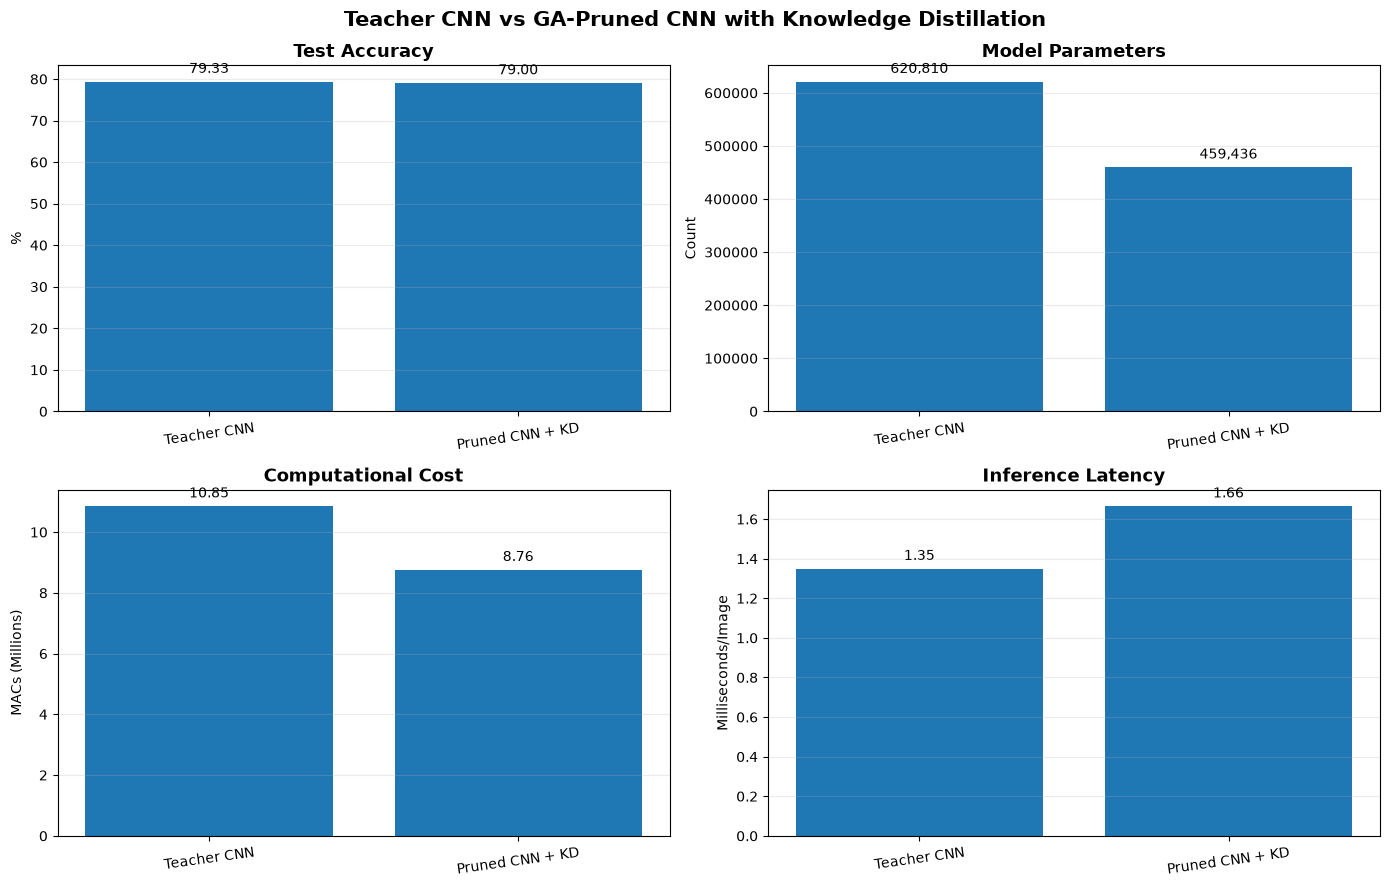


Saved successfully:
1. final_comparison_results.csv
2. final_improvements_summary.csv
3. final_comparison_graphs.png


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# ==========================================
# FINAL COMPARISON: TEACHER vs PRUNED CNN + KD
# ==========================================

teacher = {
    "Accuracy (%)": 79.33,
    "Macro Precision (%)": 79.24,
    "Macro Recall (%)": 79.33,
    "Macro F1-Score (%)": 79.27,
    "Parameters": 620810,
    "MACs (Millions)": 10.8488,
    "FLOPs (Millions)": 21.6975,
    "Latency (ms/image)": 1.3488
}

student = {
    "Accuracy (%)": 79.00,
    "Macro Precision (%)": 79.05,
    "Macro Recall (%)": 79.00,
    "Macro F1-Score (%)": 78.99,
    "Parameters": 459436,
    "MACs (Millions)": 8.7557,
    "FLOPs (Millions)": 17.5114,
    "Latency (ms/image)": 1.6645
}

# Build comparison table
comparison = pd.DataFrame({
    "Evaluation Metric": teacher.keys(),
    "Teacher CNN": teacher.values(),
    "GA-Pruned CNN + KD": student.values()
})

print("=" * 85)
print("FINAL MODEL COMPARISON")
print("GA-Based CNN Pruning with Knowledge Distillation on CIFAR-10")
print("=" * 85)

display(comparison.round(4))

# ==========================================
# CALCULATE IMPROVEMENTS
# ==========================================

parameter_reduction = (
    1 - student["Parameters"] / teacher["Parameters"]
) * 100

mac_reduction = (
    1 - student["MACs (Millions)"] / teacher["MACs (Millions)"]
) * 100

flops_reduction = (
    1 - student["FLOPs (Millions)"] / teacher["FLOPs (Millions)"]
) * 100

accuracy_difference = (
    student["Accuracy (%)"] - teacher["Accuracy (%)"]
)

latency_change = (
    student["Latency (ms/image)"] /
    teacher["Latency (ms/image)"] - 1
) * 100

print("\n" + "=" * 55)
print("KEY RESULTS")
print("=" * 55)
print(f"Parameter reduction       : {parameter_reduction:.2f}%")
print(f"MAC reduction             : {mac_reduction:.2f}%")
print(f"FLOPs reduction           : {flops_reduction:.2f}%")
print(f"Accuracy difference       : {accuracy_difference:+.2f} percentage points")
print(f"Single-image latency      : {latency_change:+.2f}%")

print("\nINTERPRETATION")
print(f"- The student has {teacher['Parameters'] - student['Parameters']:,} fewer parameters.")
print(f"- Computational cost is reduced by {mac_reduction:.2f}%.")
print(f"- Test accuracy changes by {accuracy_difference:+.2f} percentage points.")
print(f"- Measured single-image latency is {latency_change:.2f}% higher.")

# ==========================================
# VISUAL COMPARISON GRAPHS
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

chart_data = [
    ("Accuracy (%)", "Test Accuracy", "%"),
    ("Parameters", "Model Parameters", "Count"),
    ("MACs (Millions)", "Computational Cost", "MACs (Millions)"),
    ("Latency (ms/image)", "Inference Latency", "Milliseconds/Image")
]

for ax, (metric, title, ylabel) in zip(axes.flat, chart_data):
    values = [teacher[metric], student[metric]]
    bars = ax.bar(
        ["Teacher CNN", "Pruned CNN + KD"],
        values
    )
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.bar_label(
        bars,
        labels=[
            f"{values[0]:,.2f}" if values[0] < 100
            else f"{values[0]:,.0f}",
            f"{values[1]:,.2f}" if values[1] < 100
            else f"{values[1]:,.0f}"
        ],
        padding=4
    )
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=8)

plt.suptitle(
    "Teacher CNN vs GA-Pruned CNN with Knowledge Distillation",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()
plt.savefig("final_comparison_graphs.png", dpi=300, bbox_inches="tight")
plt.show()

# ==========================================
# SAVE REPORT FILES
# ==========================================

comparison.to_csv("final_comparison_results.csv", index=False)

summary = pd.DataFrame({
    "Metric": [
        "Parameter reduction (%)",
        "MAC reduction (%)",
        "FLOPs reduction (%)",
        "Accuracy difference (percentage points)",
        "Latency change (%)"
    ],
    "Result": [
        parameter_reduction,
        mac_reduction,
        flops_reduction,
        accuracy_difference,
        latency_change
    ]
})

summary.to_csv("final_improvements_summary.csv", index=False)

print("\nSaved successfully:")
print("1. final_comparison_results.csv")
print("2. final_improvements_summary.csv")
print("3. final_comparison_graphs.png")


In [1]:
import pandas as pd
from IPython.display import display

# Final experimental results
results = pd.DataFrame([
    {
        "Model": "Teacher CNN",
        "Test Accuracy (%)": 79.33,
        "Macro Precision": 0.7924,
        "Macro Recall": 0.7933,
        "Macro F1-Score": 0.7927,
        "Parameters": 620810,
        "MACs (Millions)": 10.8488,
        "FLOPs (Millions)": 21.6975,
        "Latency (ms/image)": 1.3488
    },
    {
        "Model": "GA-Pruned CNN + KD",
        "Test Accuracy (%)": 79.00,
        "Macro Precision": 0.7905,
        "Macro Recall": 0.7900,
        "Macro F1-Score": 0.7899,
        "Parameters": 459436,
        "MACs (Millions)": 8.7557,
        "FLOPs (Millions)": 17.5114,
        "Latency (ms/image)": 1.6645
    }
])

print("FINAL COMPARISON: TEACHER CNN vs PRUNED CNN + KD")
display(results.round(4))

# Save the comparison table
results.to_csv("results.csv", index=False)

print("\nSaved successfully: results.csv")

FINAL COMPARISON: TEACHER CNN vs PRUNED CNN + KD


,Model,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score,Parameters,MACs (Millions),FLOPs (Millions),Latency (ms/image)
0,Teacher CNN,79.33,0.7924,0.7933,0.7927,620810,10.8488,21.6975,1.3488
1,GA-Pruned CNN + KD,79.00,0.7905,0.7900,0.7899,459436,8.7557,17.5114,1.6645



Saved successfully: results.csv


In [2]:
teacher = results.iloc[0]
student = results.iloc[1]

parameter_reduction = (
    1 - student["Parameters"] / teacher["Parameters"]
) * 100

mac_reduction = (
    1 - student["MACs (Millions)"] /
    teacher["MACs (Millions)"]
) * 100

accuracy_difference = (
    student["Test Accuracy (%)"] -
    teacher["Test Accuracy (%)"]
)

latency_change = (
    student["Latency (ms/image)"] /
    teacher["Latency (ms/image)"] - 1
) * 100

print("=" * 50)
print("KEY EXPERIMENTAL RESULTS")
print("=" * 50)

print(f"Parameter reduction : {parameter_reduction:.2f}%")
print(f"MAC reduction       : {mac_reduction:.2f}%")
print(f"Accuracy difference : {accuracy_difference:+.2f} percentage points")
print(f"Latency change      : {latency_change:.2f}% slower")

print("\nConclusion:")
print("The proposed model reduces parameters and computation")
print("while maintaining nearly the same classification accuracy.")
print("However, measured single-image inference latency is higher.")

KEY EXPERIMENTAL RESULTS
Parameter reduction : 25.99%
MAC reduction       : 19.29%
Accuracy difference : -0.33 percentage points
Latency change      : 23.41% slower

Conclusion:
The proposed model reduces parameters and computation
while maintaining nearly the same classification accuracy.
However, measured single-image inference latency is higher.


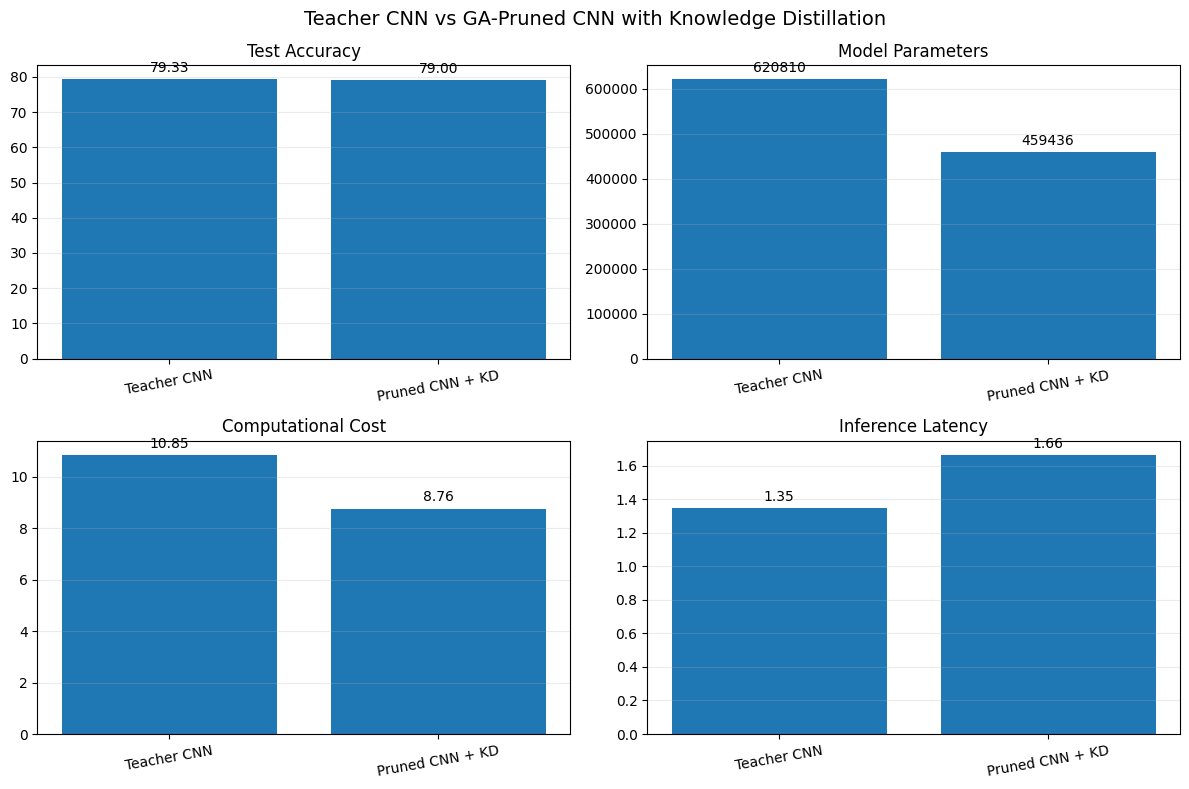

Saved successfully: final_comparison_graphs.png


In [3]:
import matplotlib.pyplot as plt

metrics = [
    ("Test Accuracy (%)", "Test Accuracy"),
    ("Parameters", "Model Parameters"),
    ("MACs (Millions)", "Computational Cost"),
    ("Latency (ms/image)", "Inference Latency")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, title) in zip(axes.flat, metrics):
    values = results[column].tolist()
    labels = ["Teacher CNN", "Pruned CNN + KD"]

    bars = ax.bar(labels, values)
    ax.set_title(title)
    ax.bar_label(bars, fmt="%.2f" if max(values) < 100 else "%.0f",
                 padding=3)
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=10)

plt.suptitle(
    "Teacher CNN vs GA-Pruned CNN with Knowledge Distillation",
    fontsize=14
)
plt.tight_layout()

plt.savefig(
    "final_comparison_graphs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved successfully: final_comparison_graphs.png")

In [4]:
from google.colab import files

files.download("results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
files.download("final_comparison_graphs.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>